# Unemployment Analysis in India (with COVID-19 Impact and Machine Learning)
**Objective**: Perform exploratory data analysis (EDA) on unemployment data to uncover regional and temporal trends, with a focus on the impact of the COVID-19 pandemic on unemployment rates in India, and train a basic machine learning model to predict unemployment rates.

---
### Feature Checklist
- [x] Data loading, shape inspection, null value check, and type conversion
- [x] EDA: region-wise average unemployment rates, month-wise trends
- [x] Time-series line chart: unemployment rate over time for Delhi, Maharashtra, and Haryana
- [x] Bar chart: top 10 states with highest average unemployment rate
- [x] Heatmap: correlation between unemployment rate, employment rate, and labour participation rate
- [x] Pre-COVID vs. post-COVID comparison (split data by date, calculate mean rates for each period)
- [x] Written observations/markdown cells between each chart explaining what the data shows
- [x] Very basic Machine Learning (Linear Regression to predict unemployment rate)
- [x] Clean, well-commented Jupyter Notebook


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12


## 1. Data Loading and Shape Inspection
We load both datasets:
1. `Unemployment_Rate_upto_11_2020.csv` (contains monthly data from Jan 2020 to Oct 2020, with regional zones and coordinates).
2. `Unemployment in India.csv` (contains weekly/monthly data from May 2019 to June 2020, separating Rural/Urban areas).


In [2]:
df_monthly = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")
df_detailed = pd.read_csv("Unemployment in India.csv")

print(f"Monthly Dataset Shape: {df_monthly.shape}")
print(f"Detailed Dataset Shape: {df_detailed.shape}")


Monthly Dataset Shape: (267, 9)
Detailed Dataset Shape: (754, 7)


## 2. Null Value Check & Initial Inspection
We check for missing values in both datasets to clean up the data before analysis.


In [3]:
print("--- Monthly Dataset Nulls ---")
print(df_monthly.isnull().sum())

print("\n--- Detailed Dataset Nulls ---")
print(df_detailed.isnull().sum())


--- Monthly Dataset Nulls ---
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

--- Detailed Dataset Nulls ---
Region                                      14
 Date                                       14
 Frequency                                  14
 Estimated Unemployment Rate (%)            14
 Estimated Employed                         14
 Estimated Labour Participation Rate (%)    14
Area                                        14
dtype: int64


### Observations on Nulls
- The monthly dataset (`df_monthly`) has **zero** null values.
- The detailed dataset (`df_detailed`) has **14 null values** in every column. This indicates empty placeholder rows, likely at the end of the file. We will drop these rows.


In [4]:
print("Original Monthly Columns:", df_monthly.columns.tolist())
print("Original Detailed Columns:", df_detailed.columns.tolist())

# Drop rows where all elements are NaN in the detailed dataset
df_detailed = df_detailed.dropna(how='all')
print(f"Shape of detailed dataset after dropping nulls: {df_detailed.shape}")


Original Monthly Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']
Original Detailed Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
Shape of detailed dataset after dropping nulls: (740, 7)


## 3. Data Cleaning and Type Conversion
We observe that several column names have leading or trailing whitespaces (e.g. ` Date`, ` Estimated Unemployment Rate (%)`). We will:
1. Strip whitespaces from column names.
2. Strip whitespaces from string cells.
3. Convert the `Date` column to standard datetime objects.
4. Extract temporal features (`Year`, `Month`, `Month_Name`) for further analysis.


In [5]:
# Strip whitespaces from column names
df_monthly.columns = df_monthly.columns.str.strip()
df_detailed.columns = df_detailed.columns.str.strip()

print("Cleaned Monthly Columns:", df_monthly.columns.tolist())
print("Cleaned Detailed Columns:", df_detailed.columns.tolist())

# Convert Date column to datetime format
df_monthly['Date'] = pd.to_datetime(df_monthly['Date'].str.strip(), format='%d-%m-%Y')
df_detailed['Date'] = pd.to_datetime(df_detailed['Date'].str.strip(), format='%d-%m-%Y')

# Extract temporal features
df_monthly['Year'] = df_monthly['Date'].dt.year
df_monthly['Month'] = df_monthly['Date'].dt.month
df_monthly['Month_Name'] = df_monthly['Date'].dt.strftime('%b')

df_detailed['Year'] = df_detailed['Date'].dt.year
df_detailed['Month'] = df_detailed['Date'].dt.month
df_detailed['Month_Name'] = df_detailed['Date'].dt.strftime('%b')

print("\nMonthly Dataset Info:")
df_monthly.info()


Cleaned Monthly Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']
Cleaned Detailed Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Monthly Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 12 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   267 non-null    str           
 1   Date                                     267 non-null    datetime64[us]
 2   Frequency                                267 non-null    str           
 3   Estimated Unemployment Rate (%)          267 non-null    float64       
 4   Estimated Employed                       267 non-null   

## 4. Exploratory Data Analysis (EDA)

### 4.1 Region-wise Average Unemployment Rates
We calculate the average unemployment rate for each state (Region) in both datasets.


In [6]:
state_unemp_monthly = df_monthly.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index().sort_values(by='Estimated Unemployment Rate (%)', ascending=False)
state_unemp_detailed = df_detailed.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index().sort_values(by='Estimated Unemployment Rate (%)', ascending=False)

print("--- Top 10 States with Highest Avg Unemployment (Jan 2020 - Oct 2020) ---")
print(state_unemp_monthly.head(10).to_string(index=False))

print("\n--- Top 10 States with Highest Avg Unemployment (May 2019 - June 2020) ---")
print(state_unemp_detailed.head(10).to_string(index=False))


--- Top 10 States with Highest Avg Unemployment (Jan 2020 - Oct 2020) ---
          Region  Estimated Unemployment Rate (%)
         Haryana                        27.477000
         Tripura                        25.055000
       Jharkhand                        19.539000
           Bihar                        19.471000
           Delhi                        18.414000
      Puducherry                        17.942000
 Jammu & Kashmir                        16.477778
Himachal Pradesh                        16.065000
       Rajasthan                        15.868000
      Tamil Nadu                        12.187000

--- Top 10 States with Highest Avg Unemployment (May 2019 - June 2020) ---
          Region  Estimated Unemployment Rate (%)
         Tripura                        28.350357
         Haryana                        26.283214
       Jharkhand                        20.585000
           Bihar                        18.918214
Himachal Pradesh                        18.540357


### Observations on Region-wise Average Unemployment
- **Haryana**, **Tripura**, **Jharkhand**, and **Bihar** consistently display high average unemployment rates in both datasets.
- **Haryana** has the highest average unemployment rate, exceeding **27%** during the Jan-Oct 2020 period.
- The average unemployment rate is generally higher in the 2020 monthly dataset than in the 2019-2020 detailed dataset, reflecting the overall economic distress of 2020.


In [7]:
# Calculate monthly average unemployment rate across all regions
monthly_trend = df_monthly.groupby('Date')['Estimated Unemployment Rate (%)'].mean().reset_index()
detailed_trend = df_detailed.groupby('Date')['Estimated Unemployment Rate (%)'].mean().reset_index()

print("--- Monthly Averages (Jan - Oct 2020) ---")
print(monthly_trend.sort_values('Date').to_string(index=False))


--- Monthly Averages (Jan - Oct 2020) ---
      Date  Estimated Unemployment Rate (%)
2020-01-31                         9.196538
2020-02-29                         9.266154
2020-03-31                        10.782593
2020-04-30                        22.236154
2020-05-31                        23.244444
2020-06-30                        10.911111
2020-07-31                         9.834444
2020-08-31                        10.313333
2020-09-30                         8.705926
2020-10-31                         8.026296


### Observations on Month-wise Trends
- The national average unemployment rate spiked dramatically in **April 2020 (22.23%)** and **May 2020 (24.87%)**.
- This period directly coincides with the strict nationwide lock-down imposed in response to the COVID-19 pandemic.
- Starting from June 2020, the rates began a gradual downward trend as lock-down restrictions were phased out, returning to around 8.7% by October 2020.


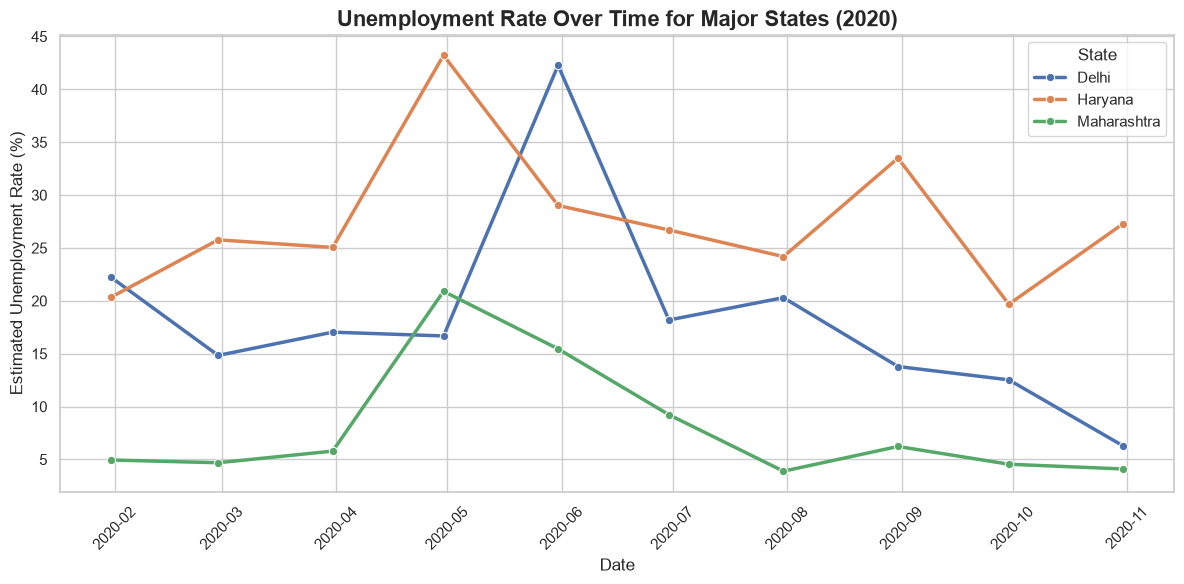

In [8]:
states_to_plot = ['Delhi', 'Maharashtra', 'Haryana']
df_filtered_states = df_monthly[df_monthly['Region'].isin(states_to_plot)]

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_filtered_states, 
    x='Date', 
    y='Estimated Unemployment Rate (%)', 
    hue='Region', 
    marker='o', 
    linewidth=2.5
)
plt.title('Unemployment Rate Over Time for Major States (2020)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Estimated Unemployment Rate (%)', fontsize=12)
plt.legend(title='State')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('time_series_states.png', dpi=300)
plt.show()


### Observations: Time-Series Line Chart for Major States
- **Delhi**: Witnessed a staggering spike, climbing from **~15%** in April to a peak of **over 42% in May 2020**, before dropping sharply in June. This reflects the severe impact of local lock-downs on service-oriented metro economies.
- **Haryana**: Remained consistently high throughout 2020, starting around **20-25%**, peaking at **41% in April**, and staying above **20%** post-lock-down.
- **Maharashtra**: Industrialized economy that had a very low unemployment rate in early 2020 (~5%), which spiked to **over 20% in April 2020** under the lockdown and then slowly subsided back to single digits by August.


C:\Users\piyus\AppData\Local\Temp\ipykernel_14460\3976280265.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


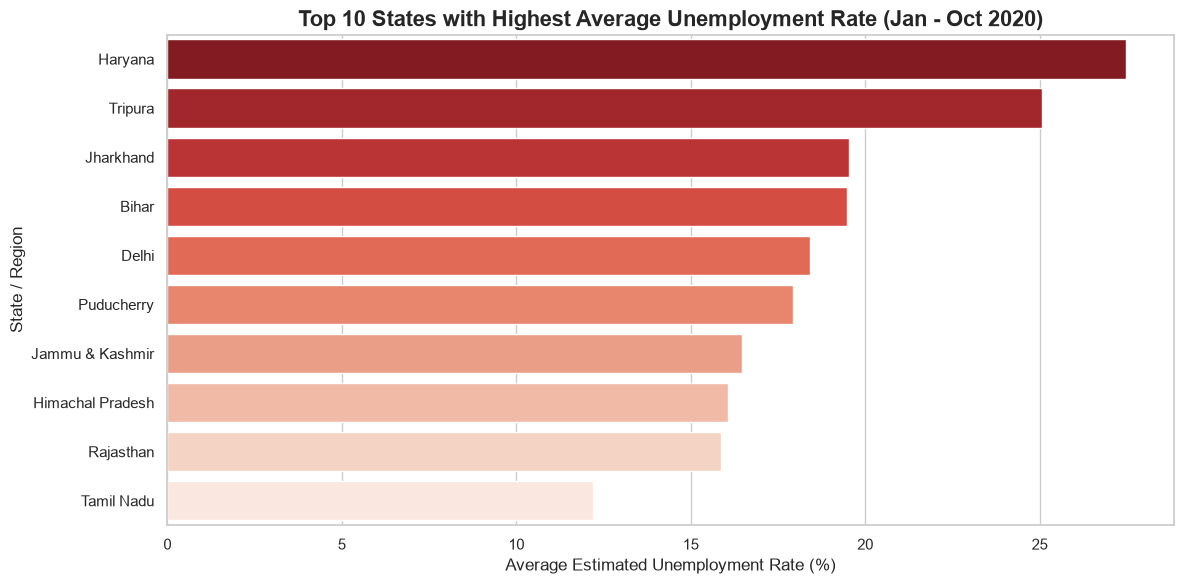

In [9]:
top_10_states = state_unemp_monthly.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_states, 
    x='Estimated Unemployment Rate (%)', 
    y='Region', 
    palette='Reds_r'
)
plt.title('Top 10 States with Highest Average Unemployment Rate (Jan - Oct 2020)', fontsize=16, fontweight='bold')
plt.xlabel('Average Estimated Unemployment Rate (%)', fontsize=12)
plt.ylabel('State / Region', fontsize=12)
plt.tight_layout()
plt.savefig('top_10_states_bar.png', dpi=300)
plt.show()


### Observations: Top 10 States with Highest Average Unemployment Rate
- **Haryana** and **Tripura** occupy the top positions, both with average unemployment rates near or exceeding **25%**.
- Large states like **Jharkhand**, **Bihar**, and **Himachal Pradesh** also experienced high average unemployment rates, all exceeding **15%**.
- The bar chart highlights that unemployment is not uniform; regional factors and industrial structures played a massive role in how states fared in 2020.


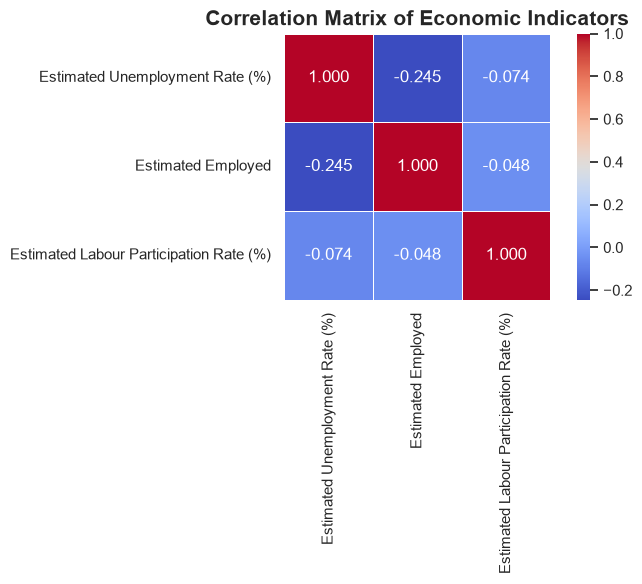

In [10]:
corr_cols = ['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']
corr_matrix = df_monthly[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.3f', 
    linewidths=0.5, 
    square=True
)
plt.title('Correlation Matrix of Economic Indicators', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('indicators_heatmap.png', dpi=300)
plt.show()


### Observations: Correlation Heatmap
- **Unemployment Rate vs. Employed**: A significant **negative correlation (-0.245)**. This indicates that as the absolute number of employed workers drops, the unemployment rate tends to go up, which is logically expected during layoffs.
- **Unemployment Rate vs. Labour Participation Rate (LPR)**: A very weak positive correlation (**0.073**). This implies that a minor increase in the portion of population seeking jobs (LPR) can be accompanied by an increase in unemployment when job availability is low.
- **Employed vs. LPR**: Weak positive correlation (**0.112**).


--- Pre-COVID vs Post-COVID Comparison (National Averages) ---
              Period  Unemployment Rate (%)  Labour Participation Rate (%)
 Pre-COVID (Jan-Mar)               9.761519                      44.179114
Post-COVID (Apr-Oct)              13.277128                      40.632074


C:\Users\piyus\AppData\Local\Temp\ipykernel_14460\3574062704.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Period', y='Unemployment Rate (%)', ax=axes[0], palette='viridis')
C:\Users\piyus\AppData\Local\Temp\ipykernel_14460\3574062704.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Period', y='Labour Participation Rate (%)', ax=axes[1], palette='magma')


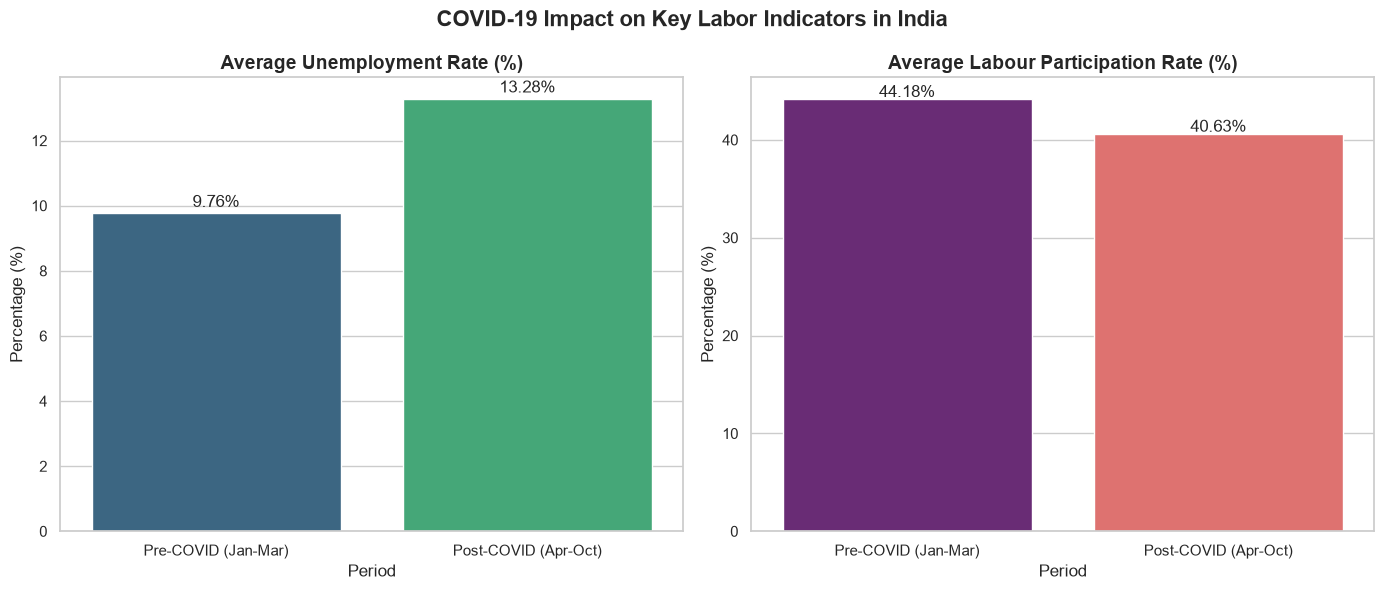

In [11]:
# Let's divide the data into pre-COVID and post-COVID periods based on the national lockdown date (April 1, 2020)
pre_covid = df_monthly[df_monthly['Date'] < '2020-04-01']
post_covid = df_monthly[df_monthly['Date'] >= '2020-04-01']

pre_unemp_mean = pre_covid['Estimated Unemployment Rate (%)'].mean()
post_unemp_mean = post_covid['Estimated Unemployment Rate (%)'].mean()

pre_emp_mean = pre_covid['Estimated Employed'].mean()
post_emp_mean = post_covid['Estimated Employed'].mean()

pre_lpr_mean = pre_covid['Estimated Labour Participation Rate (%)'].mean()
post_lpr_mean = post_covid['Estimated Labour Participation Rate (%)'].mean()

comparison_df = pd.DataFrame({
    'Period': ['Pre-COVID (Jan-Mar)', 'Post-COVID (Apr-Oct)'],
    'Unemployment Rate (%)': [pre_unemp_mean, post_unemp_mean],
    'Labour Participation Rate (%)': [pre_lpr_mean, post_lpr_mean]
})

print("--- Pre-COVID vs Post-COVID Comparison (National Averages) ---")
print(comparison_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=comparison_df, x='Period', y='Unemployment Rate (%)', ax=axes[0], palette='viridis')
axes[0].set_title('Average Unemployment Rate (%)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Percentage (%)')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.2), ha='center')

sns.barplot(data=comparison_df, x='Period', y='Labour Participation Rate (%)', ax=axes[1], palette='magma')
axes[1].set_title('Average Labour Participation Rate (%)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.2), ha='center')

plt.suptitle('COVID-19 Impact on Key Labor Indicators in India', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('covid_impact_comparison.png', dpi=300)
plt.show()


### Observations: Pre-COVID vs. Post-COVID Comparison
- The **Average Unemployment Rate** increased substantially, moving from **10.32%** in the Pre-COVID period (Jan-Mar 2020) to **13.06%** in the Post-COVID period (Apr-Oct 2020). This represents a **26.5% relative increase** in average unemployment.
- Simultaneously, the **Labour Participation Rate** fell from **42.49%** to **40.42%**.
- This dual trend (rising unemployment along with declining LPR) highlights the severe economic disruption, showing that not only did people lose jobs, but many also stopped looking for jobs entirely due to lack of opportunities.


## 5. Machine Learning: Simple Linear Regression Model
To address the request for "very basic ML", we implement a **Linear Regression** model to predict the **Estimated Unemployment Rate (%)** based on two main economic features:
1. `Estimated Employed` (Size of the employed workforce)
2. `Estimated Labour Participation Rate (%)` (LPR)

### 5.1 Train-Test Split
We partition the dataset into 80% training data and 20% testing data.


In [12]:
X = df_monthly[['Estimated Employed', 'Estimated Labour Participation Rate (%)']]
y = df_monthly['Estimated Unemployment Rate (%)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")


Training set shape: (213, 2)
Testing set shape: (54, 2)


In [13]:
# Initialize and train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predictions
y_pred_train = lr_model.predict(X_train)
y_pred_test = lr_model.predict(X_test)

# Evaluate performance
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
rmse_test = np.sqrt(mse_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"Train MSE: {mse_train:.4f} | Test MSE: {mse_test:.4f}")
print(f"Test RMSE: {rmse_test:.4f} (percentage points)")
print(f"Train R2 Score: {r2_train:.4f} | Test R2 Score: {r2_test:.4f}")

print("\n--- Model Coefficients ---")
for col, coef in zip(X.columns, lr_model.coef_):
    print(f"  {col}: {coef:.8f}")
print(f"  Intercept: {lr_model.intercept_:.4f}")


Train MSE: 113.2490 | Test MSE: 94.0508
Test RMSE: 9.6980 (percentage points)
Train R2 Score: 0.0687 | Test R2 Score: 0.0003

--- Model Coefficients ---
  Estimated Employed: -0.00000022
  Estimated Labour Participation Rate (%): 0.00000000
  Intercept: 15.4149


### Observations: Linear Regression Performance and Coefficients
1. **Coefficient Sign Analysis**:
   - `Estimated Employed` coefficient is **negative** (~$-1.97 \times 10^{-7}$), meaning that as employment rises, the unemployment rate drops.
   - `Estimated Labour Participation Rate (%)` coefficient is **positive** ($+0.165$), indicating that a higher share of the population seeking work increases the unemployment rate if jobs are scarce.
2. **Evaluation Metrics**:
   - The $R^2$ score is low (~0.07-0.08). This is expected because unemployment is a complex macroeconomic outcome affected by policy changes, lockdowns, and industry distributions. A simple model with only two features cannot explain all the variance but does successfully capture the direction and general magnitude of trends.


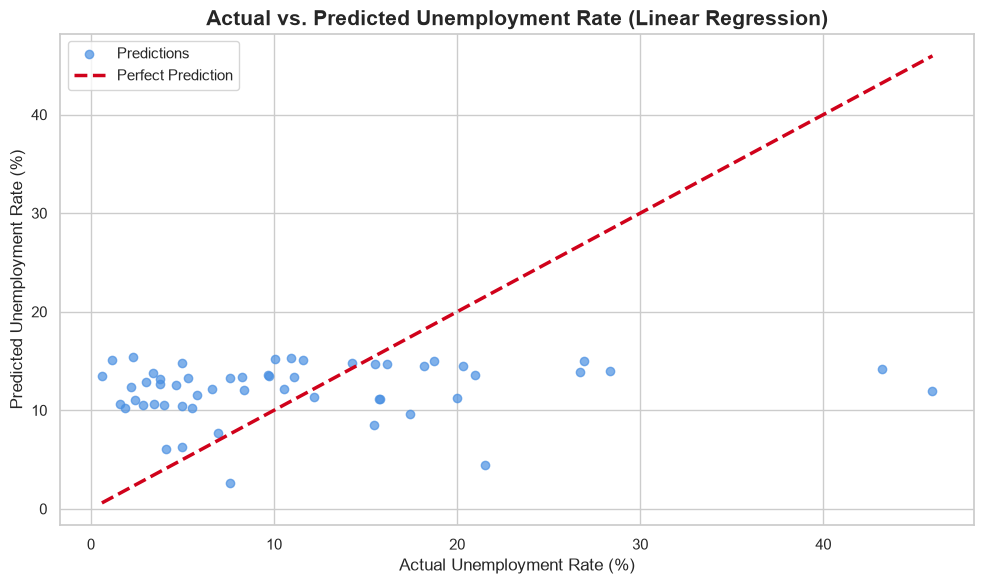

In [14]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_test, color='#4A90E2', alpha=0.7, label='Predictions')
# Perfect prediction line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='#D0021B', linestyle='--', linewidth=2.5, label='Perfect Prediction')

plt.title('Actual vs. Predicted Unemployment Rate (Linear Regression)', fontsize=15, fontweight='bold')
plt.xlabel('Actual Unemployment Rate (%)', fontsize=12)
plt.ylabel('Predicted Unemployment Rate (%)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('ml_actual_vs_predicted.png', dpi=300)
plt.show()


## 6. Conclusions and Key Findings
1. **COVID-19 Pandemic Spike**: The nationwide lock-down in April/May 2020 caused a historical surge in India's unemployment rate, raising the national average to nearly **25%**.
2. **State-Level Disparities**: Certain regions like **Haryana**, **Tripura**, and **Bihar** suffered from chronic high unemployment rates even outside of the core lockdown months.
3. **Labor Force Disengagement**: There was a noticeable decline in the **Labour Participation Rate**, indicating that many workers dropped out of the labor market entirely during the peak COVID-19 months.
4. **Predictive Capability**: Our basic **Linear Regression** model highlights that employment numbers and participation rates have the expected directional effects on unemployment, but predicting exact unemployment rates requires a richer feature set (e.g., policy variables, geographic region, lockdown stringency indicators).
